In [1]:
import pandas as pd
import numpy as np
import os
import joblib

from catboost import CatBoostRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_squared_log_error
)

BASE_DIR = r"C:\Users\vikra\Desktop\Supply Chain Algo"

DATA_PATH = os.path.join(
    BASE_DIR,
    "Data",
    "processed",
    "sales_features.csv.gz"
)

df = pd.read_csv(DATA_PATH)

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values(
    ["date", "store_nbr", "family"]
).reset_index(drop=True)

print("Dataset Shape:", df.shape)
print("Date Range:", df["date"].min(), "to", df["date"].max())

Dataset Shape: (2950992, 33)
Date Range: 2013-01-29 00:00:00 to 2017-08-15 00:00:00


In [2]:
# Final 16 days are reserved for testing
last_date = df["date"].max()

test_start = last_date - pd.Timedelta(days=15)

development_df = df[
    df["date"] < test_start
].copy()

test_df = df[
    df["date"] >= test_start
].copy()

# Previous 16 days are used for hyperparameter validation
tune_start = (
    development_df["date"].max()
    - pd.Timedelta(days=15)
)

tune_train_df = development_df[
    development_df["date"] < tune_start
].copy()

tune_valid_df = development_df[
    development_df["date"] >= tune_start
].copy()

print("Tuning Training:", tune_train_df.shape)
print("Tuning Validation:", tune_valid_df.shape)
print("Final Test:", test_df.shape)

print("\nTuning validation days:",
      tune_valid_df["date"].nunique())

print("Final test days:",
      test_df["date"].nunique())

Tuning Training: (2893968, 33)
Tuning Validation: (28512, 33)
Final Test: (28512, 33)

Tuning validation days: 16
Final test days: 16


In [3]:
assert tune_train_df["date"].max() < tune_valid_df["date"].min()

assert tune_valid_df["date"].max() < test_df["date"].min()

assert tune_valid_df["date"].nunique() == 16
assert test_df["date"].nunique() == 16

print("Chronological datasets validated!")

Chronological datasets validated!


In [4]:
categorical_features = [
    "store_nbr",
    "family"
]

numeric_features = [
    "onpromotion",
    "has_holiday_event",
    "holiday_event_count",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "quarter",
    "is_weekend",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

categorical_features = [
    c for c in categorical_features if c in df.columns
]

numeric_features = [
    c for c in numeric_features if c in df.columns
]

feature_columns = categorical_features + numeric_features

print("Total features:", len(feature_columns))

Total features: 24


In [5]:
def prepare_features(data):

    X = data[feature_columns].copy()

    for col in categorical_features:
        X[col] = (
            X[col]
            .fillna("Unknown")
            .astype(str)
        )

    return X

In [6]:
TUNE_SAMPLE_SIZE = 100_000

tune_train_sample = tune_train_df.sample(
    n=min(TUNE_SAMPLE_SIZE, len(tune_train_df)),
    random_state=42
)

X_tune_train = prepare_features(tune_train_sample)
X_tune_valid = prepare_features(tune_valid_df)

y_tune_train = np.log1p(
    tune_train_sample["sales"].clip(lower=0)
)

y_tune_valid = tune_valid_df["sales"].clip(lower=0)

y_tune_valid_log = np.log1p(y_tune_valid)

print("Training:", X_tune_train.shape)
print("Validation:", X_tune_valid.shape)

Training: (100000, 24)
Validation: (28512, 24)


In [7]:
def evaluate_model(y_true, y_pred, model_name):

    y_true = np.maximum(np.asarray(y_true), 0)
    y_pred = np.maximum(np.asarray(y_pred), 0)

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    rmsle = np.sqrt(
        mean_squared_log_error(y_true, y_pred)
    )

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / max(np.sum(y_true), 1e-10)
    ) * 100

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "RMSLE": rmsle,
        "WAPE (%)": wape
    }

In [8]:
param_configs = [
    {
        "depth": 6,
        "learning_rate": 0.05,
        "l2_leaf_reg": 5
    },
    {
        "depth": 8,
        "learning_rate": 0.05,
        "l2_leaf_reg": 5
    },
    {
        "depth": 6,
        "learning_rate": 0.03,
        "l2_leaf_reg": 10
    },
    {
        "depth": 8,
        "learning_rate": 0.03,
        "l2_leaf_reg": 10
    }
]

print("Configurations to test:", len(param_configs))

Configurations to test: 4


In [9]:
tuning_results = []
tuning_models = []

for i, params in enumerate(param_configs):

    print(f"\nTraining configuration {i+1}")
    print("Parameters:", params)

    model = CatBoostRegressor(
        iterations=1200,
        depth=params["depth"],
        learning_rate=params["learning_rate"],
        l2_leaf_reg=params["l2_leaf_reg"],
        loss_function="RMSE",
        eval_metric="RMSE",
        random_seed=42,
        verbose=200,
        thread_count=-1,
        allow_writing_files=False
    )

    model.fit(
        X_tune_train,
        y_tune_train,
        cat_features=categorical_features,
        eval_set=(X_tune_valid, y_tune_valid_log),
        early_stopping_rounds=100,
        verbose=200
    )

    # Predictions on tuning validation
    predictions_log = model.predict(X_tune_valid)

    predictions = np.maximum(
        np.expm1(predictions_log),
        0
    )

    metrics = evaluate_model(
        y_tune_valid,
        predictions,
        f"CatBoost Config {i+1}"
    )

    result = {
        "Configuration": i+1,
        **params,
        "Best Iteration": model.get_best_iteration() + 1,
        **metrics
    }

    tuning_results.append(result)
    tuning_models.append(model)

    print("Evaluation:", result)

print("\nAll configurations trained!")


Training configuration 1
Parameters: {'depth': 6, 'learning_rate': 0.05, 'l2_leaf_reg': 5}
0:	learn: 2.5736341	test: 2.5104775	best: 2.5104775 (0)	total: 208ms	remaining: 4m 9s
200:	learn: 0.4210451	test: 0.3965932	best: 0.3965932 (200)	total: 15.2s	remaining: 1m 15s
400:	learn: 0.4026861	test: 0.3902788	best: 0.3902788 (400)	total: 30.4s	remaining: 1m
600:	learn: 0.3931738	test: 0.3872443	best: 0.3872443 (600)	total: 44.7s	remaining: 44.5s
800:	learn: 0.3868257	test: 0.3856388	best: 0.3856388 (800)	total: 59.2s	remaining: 29.5s
1000:	learn: 0.3818105	test: 0.3847786	best: 0.3847786 (1000)	total: 1m 13s	remaining: 14.7s
1199:	learn: 0.3778078	test: 0.3841190	best: 0.3841190 (1199)	total: 1m 28s	remaining: 0us

bestTest = 0.384118988
bestIteration = 1199

Evaluation: {'Configuration': 1, 'depth': 6, 'learning_rate': 0.05, 'l2_leaf_reg': 5, 'Best Iteration': 1200, 'Model': 'CatBoost Config 1', 'MAE': 59.93703986017961, 'RMSE': np.float64(219.88223793079976), 'RMSLE': np.float64(0.384104

In [10]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="WAPE (%)"
).reset_index(drop=True)

display(tuning_df)

,Configuration,depth,learning_rate,l2_leaf_reg,Best Iteration,Model,MAE,RMSE,RMSLE,WAPE (%)
0,2,8,0.05,5,1191,CatBoost Config 2,58.922092,216.125348,0.382716,12.230513
1,1,6,0.05,5,1200,CatBoost Config 1,59.937040,219.882238,0.384104,12.441187
2,4,8,0.03,10,1199,CatBoost Config 4,60.202994,219.095344,0.383923,12.496391
3,3,6,0.03,10,1200,CatBoost Config 3,61.579447,223.072698,0.385939,12.782103


In [11]:
best_config_number = int(
    tuning_df.iloc[0]["Configuration"]
)

best_model = tuning_models[
    best_config_number - 1
]

best_params = param_configs[
    best_config_number - 1
]

print("Best configuration:", best_config_number)
print("Best parameters:", best_params)
print("Best iteration:", best_model.get_best_iteration() + 1)

Best configuration: 2
Best parameters: {'depth': 8, 'learning_rate': 0.05, 'l2_leaf_reg': 5}
Best iteration: 1191


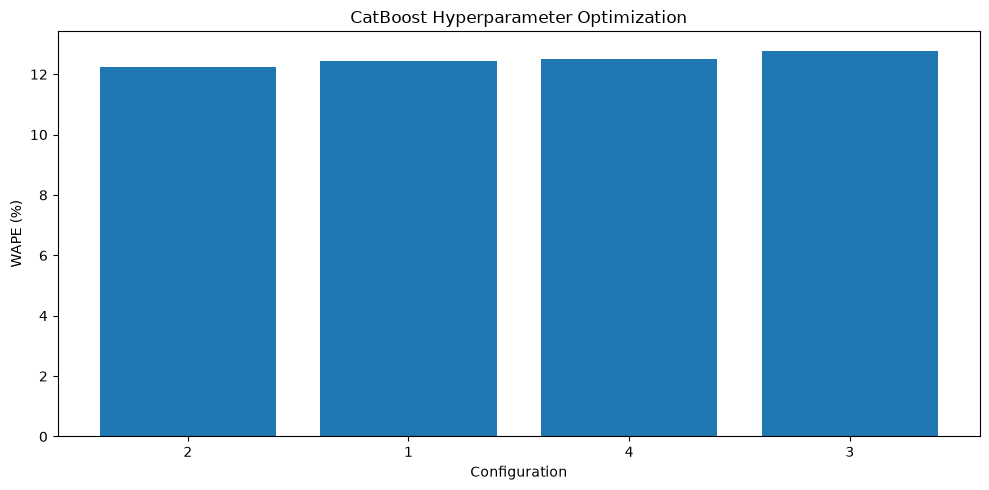

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    tuning_df["Configuration"].astype(str),
    tuning_df["WAPE (%)"]
)

plt.title("CatBoost Hyperparameter Optimization")
plt.xlabel("Configuration")
plt.ylabel("WAPE (%)")
plt.tight_layout()
plt.show()

In [13]:
FINAL_SAMPLE_SIZE = 150_000

final_train_sample = development_df.sample(
    n=min(FINAL_SAMPLE_SIZE, len(development_df)),
    random_state=42
)

X_final_train = prepare_features(final_train_sample)

y_final_train = np.log1p(
    final_train_sample["sales"].clip(lower=0)
)

X_test = prepare_features(test_df)

y_test = test_df["sales"].clip(lower=0)

best_iterations = best_model.get_best_iteration() + 1

if best_iterations <= 0:
    best_iterations = best_model.tree_count_

print("Final training sample:", X_final_train.shape)
print("Final test data:", X_test.shape)
print("Selected iterations:", best_iterations)

Final training sample: (150000, 24)
Final test data: (28512, 24)
Selected iterations: 1191


In [14]:
final_model = CatBoostRegressor(
    iterations=best_iterations,
    depth=best_params["depth"],
    learning_rate=best_params["learning_rate"],
    l2_leaf_reg=best_params["l2_leaf_reg"],
    loss_function="RMSE",
    random_seed=42,
    verbose=200,
    thread_count=-1,
    allow_writing_files=False
)

final_model.fit(
    X_final_train,
    y_final_train,
    cat_features=categorical_features
)

print("Final optimized model trained!")

0:	learn: 2.5666431	total: 105ms	remaining: 2m 5s
200:	learn: 0.4008155	total: 21.6s	remaining: 1m 46s
400:	learn: 0.3833395	total: 44.2s	remaining: 1m 27s
600:	learn: 0.3735230	total: 1m 7s	remaining: 1m 5s
800:	learn: 0.3661311	total: 1m 29s	remaining: 43.5s
1000:	learn: 0.3597883	total: 1m 52s	remaining: 21.4s
1190:	learn: 0.3549036	total: 2m 15s	remaining: 0us
Final optimized model trained!


In [15]:
final_predictions_log = final_model.predict(X_test)

final_predictions = np.maximum(
    np.expm1(final_predictions_log),
    0
)

final_result = evaluate_model(
    y_test,
    final_predictions,
    "Optimized CatBoost"
)

print(final_result)

{'Model': 'Optimized CatBoost', 'MAE': 63.314264649292326, 'RMSE': np.float64(214.8322152662807), 'RMSLE': np.float64(0.38783334551325704), 'WAPE (%)': np.float64(13.553509625029337)}


In [16]:
test_baselines = []

for name, col in [
    ("Previous Day", "sales_lag_1"),
    ("Same Day Last Week", "sales_lag_7"),
    ("7-Day Moving Average", "sales_rolling_mean_7")
]:

    result = evaluate_model(
        y_test,
        test_df[col],
        name
    )

    test_baselines.append(result)

final_comparison = pd.DataFrame(
    test_baselines + [final_result]
)

display(
    final_comparison.sort_values("WAPE (%)")
)

,Model,MAE,RMSE,RMSLE,WAPE (%)
3,Optimized CatBoost,63.314265,214.832215,0.387833,13.553510
2,7-Day Moving Average,90.839535,297.306315,0.448937,19.445768
1,Same Day Last Week,100.230365,350.060513,0.569367,21.456037
0,Previous Day,112.703159,386.907178,0.546108,24.126054


In [17]:
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": final_model.get_feature_importance()
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
21,sales_rolling_mean_7,27.547875
17,sales_lag_1,18.123753
18,sales_lag_7,10.896551
22,sales_rolling_mean_14,9.727153
19,sales_lag_14,7.984053
23,sales_rolling_mean_28,5.537479
9,day_of_year,5.159844
1,family,3.342342
20,sales_lag_28,3.217119
7,day,1.736184


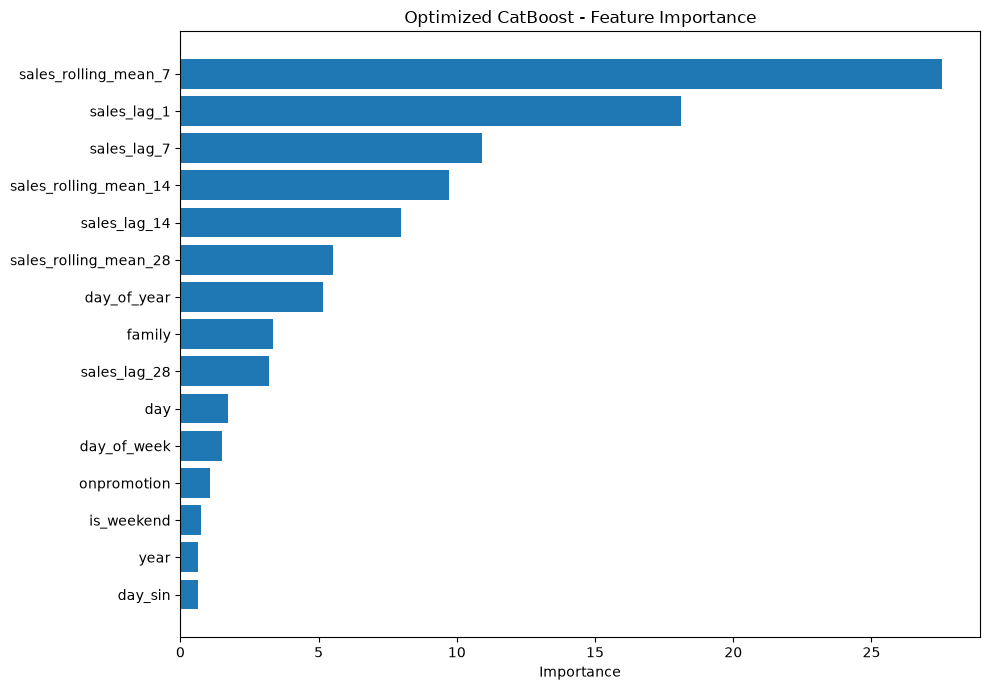

In [18]:
top_features = importance_df.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Optimized CatBoost - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [19]:
MODEL_DIR = os.path.join(BASE_DIR, "models")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

# Save model
final_model.save_model(
    os.path.join(
        MODEL_DIR,
        "optimized_catboost_model.cbm"
    )
)

# Save tuning results
tuning_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "catboost_tuning_results.csv"
    ),
    index=False
)

# Save final comparison
final_comparison.to_csv(
    os.path.join(
        REPORT_DIR,
        "final_test_comparison.csv"
    ),
    index=False
)

# Save test predictions
prediction_report = test_df[
    ["date", "store_nbr", "family"]
].copy()

prediction_report["actual_sales"] = y_test.values
prediction_report["predicted_sales"] = final_predictions

prediction_report.to_csv(
    os.path.join(
        REPORT_DIR,
        "optimized_catboost_predictions.csv"
    ),
    index=False
)

print("Optimized model and reports saved successfully!")

Optimized model and reports saved successfully!
